In [29]:
import torch
import torch.nn as nn
import pandas as pd
import matplotlib.pyplot as plt

torch.manual_seed(0)

def make_mlp(depth, activation="tanh", width=64, in_features=10):
    layers = []
    current = in_features
    for _ in range(depth):
        layers.append(nn.Linear(current, width))
        if activation == "tanh":
            layers.append(nn.Tanh())
        elif activation == "relu":
            layers.append(nn.ReLU())
        else:
            raise ValueError("Unsupported activation")
        current = width
    layers.append(nn.Linear(current, 1))
    return nn.Sequential(*layers)

def grad_norm_for_depth(depth, activation):
    model = make_mlp(depth, activation)
    x = torch.randn(128, 10)  # synthetic inputs
    y = model(x).sum()        # scalar loss
    model.zero_grad()
    y.backward()

    # Gradient norm of the first Linear layer
    first_linear = [m for m in model.modules() if isinstance(m, nn.Linear)][0]
    grad_norm = first_linear.weight.grad.norm().item()
    return grad_norm

rows = []
for activation in ["tanh", "relu"]:
    for depth in [2, 4, 8, 16]:
        gnorm = grad_norm_for_depth(depth, activation)
        rows.append({
            "activation": activation,
            "depth": depth,
            "grad_norm": gnorm
        })

df_grad = pd.DataFrame(rows)
df_grad

,activation,depth,grad_norm
0,tanh,2,9.934779
1,tanh,4,3.234288
2,tanh,8,0.417927
3,tanh,16,0.003391
4,relu,2,13.355686
5,relu,4,2.339671
6,relu,8,0.044196
7,relu,16,0.000040


In [30]:
import math

def make_deep_relu(depth=10, width=64, in_features=10):
    layers = []
    current = in_features
    for _ in range(depth):
        layers.append(nn.Linear(current, width))
        layers.append(nn.ReLU())
        current = width
    layers.append(nn.Linear(current, 1))
    return nn.Sequential(*layers)

def grad_norm_for_init(std, trials=10):
    norms = []
    for _ in range(trials):
        model = make_deep_relu()
        # Custom initialization
        with torch.no_grad():
            for m in model.modules():
                if isinstance(m, nn.Linear):
                    m.weight.normal_(mean=0.0, std=std)
                    m.bias.zero_()

        x = torch.randn(128, 10)
        y = model(x).sum()
        model.zero_grad()
        y.backward()

        # Collect gradient norms from all Linear layers
        gnorms = []
        for m in model.modules():
            if isinstance(m, nn.Linear) and m.weight.grad is not None:
                gnorms.append(m.weight.grad.norm().item())
        norms.append(sum(gnorms) / len(gnorms))
    return sum(norms) / len(norms)

rows_init = []
for std in [0.01, 0.1, 1.0]:
    avg_g = grad_norm_for_init(std, trials=10)
    rows_init.append({"std": std, "avg_grad_norm": avg_g})

df_init = pd.DataFrame(rows_init)
df_init

,std,avg_grad_norm
0,0.01,7.094623e-11
1,0.10,7.497013e-01
2,1.00,6.453819e+09


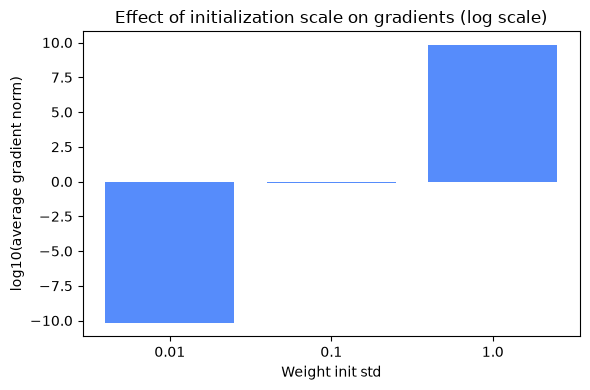

In [31]:
# Plot log10 of the average gradient norm
import numpy as np
log_vals = np.log10(df_init["avg_grad_norm"].values)

plt.figure(figsize=(6, 4))
plt.bar(df_init["std"].astype(str), log_vals)
plt.xlabel("Weight init std")
plt.ylabel("log10(average gradient norm)")
plt.title("Effect of initialization scale on gradients (log scale)")
plt.tight_layout()
plt.show()